# SVD of a 2×3 Matrix with NumPy + Geometric Animation (Self‑Contained)

This notebook computes the SVD of a 2×3 matrix using **NumPy** and visualizes the mapping\n**V^T → Σ → U** with a clear 3D/2D animation. The **XZ plane** is kept flat and the **Y‑axis** is vertical\nso the rotation about Y is easy to see.\n
**How to use**: Edit `A` in Section 1 and run all cells. The SVD and the animation will update automatically.


## 1) Define matrix `A` and compute SVD with NumPy


In [1]:

import numpy as np
np.set_printoptions(precision=6, suppress=True)

# --- Define your 2x3 matrix here (must be shape 2x3) ---
rt2 = np.sqrt(2.0)
A = np.array([[4.0, -2*rt2, 4.0],
              [4.0,  2*rt2, 4.0]], dtype=float)

# Sanity check
if A.shape != (2,3):
    raise ValueError(f"This notebook expects A to be 2x3. Got {A.shape}.")

# --- SVD via NumPy ---
# For A in R^{2x3}, full_matrices=True gives U(2x2), S(2,), Vt(3x3)
U, S, Vt = np.linalg.svd(A, full_matrices=True)
print("Full SVD:\n")
print("A =\n", A)
print("\nU (2x2) =\n", U)
print("\nSingular values S =\n", S)
print("\nV^T (3x3) =\n", Vt)

# --- Reduced SVD via NumPy ---
# For A in R^{2x3}, full_matrices=False gives U(2x2), S(2,), Vt(2x3)
U, S, Vt = np.linalg.svd(A, full_matrices=False)
print("\n\nReduced SVD:\n")
print("A =\n", A)
print("\nU (2x2) =\n", U)
print("\nSingular values S =\n", S)
print("\nV^T (2x3) =\n", Vt)



# Correct reconstruction for reduced SVD
A_recon = U @ np.diag(S) @ Vt
recon_err = np.max(np.abs(A - A_recon))

# Moore–Penrose pseudoinverse via reduced SVD: A^+ = V diag(1/S) U^T
tol  = np.finfo(float).eps * max(A.shape) * (S[0] if S.size else 1.0)
invS = np.zeros_like(S)
invS[S > tol] = 1.0 / S[S > tol]
A_pinv = Vt.T @ np.diag(invS) @ U.T   # (3x2)(2x2)(2x2) -> (3x2)

# Optional rectangular Sigma (2x3) for display only (not used in multiplication)
Sigma_rect = np.zeros_like(A)
if S.size > 0:
    Sigma_rect[0,0] = S[0]
if S.size > 1:
    Sigma_rect[1,1] = S[1]


print("\nRectangular Sigma (2x3) [display only] =\n", Sigma_rect)
print("\nReconstruction error ||A - U Σ V^T||_max =", recon_err)
print("\nPseudoinverse A^+ =\n", A_pinv)

# Keep handy for animation
U_svd, S_svd, Vt_svd = U.copy(), S.copy(), Vt.copy()


Full SVD:

A =
 [[ 4.       -2.828427  4.      ]
 [ 4.        2.828427  4.      ]]

U (2x2) =
 [[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]

Singular values S =
 [8. 4.]

V^T (3x3) =
 [[ 0.707107  0.        0.707107]
 [-0.        1.        0.      ]
 [-0.707107 -0.        0.707107]]


Reduced SVD:

A =
 [[ 4.       -2.828427  4.      ]
 [ 4.        2.828427  4.      ]]

U (2x2) =
 [[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]

Singular values S =
 [8. 4.]

V^T (2x3) =
 [[ 0.707107  0.        0.707107]
 [-0.        1.        0.      ]]

Rectangular Sigma (2x3) [display only] =
 [[8. 0. 0.]
 [0. 4. 0.]]

Reconstruction error ||A - U Σ V^T||_max = 1.7763568394002505e-15

Pseudoinverse A^+ =
 [[ 0.0625    0.0625  ]
 [-0.176777  0.176777]
 [ 0.0625    0.0625  ]]


## 2) Geometric animation (XZ plane flat, Y vertical)


Saved: SVD_VSU_animation.gif


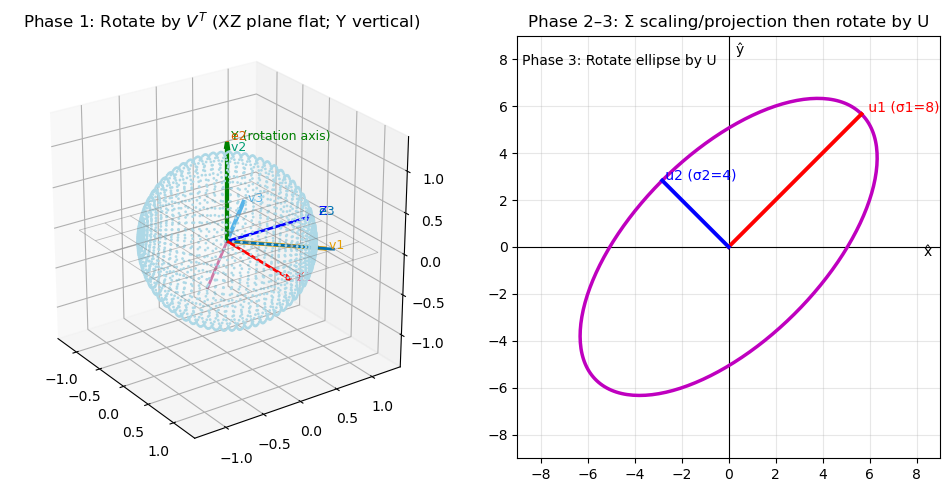

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.mplot3d import Axes3D

# ---------------- Utilities ----------------
def make_V_full(Vt):
    """Given reduced Vt (r×n) with n=3, build a proper 3×3 V with columns v1,v2,v3 (det=+1)."""
    Vred = Vt.T            # n×r (here 3×2)
    vecs = []
    for i in range(Vred.shape[1]):
        v = Vred[:, i]
        nv = np.linalg.norm(v)
        if nv > 0:
            vecs.append(v / nv)
    if len(vecs) == 0:
        V_full = np.eye(3)
    elif len(vecs) == 1:
        v1 = vecs[0]
        tmp = np.array([1.0,0.0,0.0])
        if abs(np.dot(tmp, v1)) > 0.9:
            tmp = np.array([0.0,1.0,0.0])
        v2 = tmp - np.dot(tmp, v1)*v1
        v2 /= np.linalg.norm(v2)
        v3 = np.cross(v1, v2)
        V_full = np.column_stack([v1, v2, v3])
        if np.linalg.det(V_full) < 0:
            V_full[:,2] *= -1
    else:
        v1 = vecs[0]
        v2 = vecs[1] - np.dot(vecs[1], v1)*v1
        n2 = np.linalg.norm(v2)
        if n2 > 0:
            v2 /= n2
        else:
            tmp = np.array([1.0,0.0,0.0])
            if abs(np.dot(tmp, v1)) > 0.9:
                tmp = np.array([0.0,1.0,0.0])
            v2 = tmp - np.dot(tmp, v1)*v1
            v2 /= np.linalg.norm(v2)
        v3 = np.cross(v1, v2)
        V_full = np.column_stack([v1, v2, v3])
        if np.linalg.det(V_full) < 0:
            V_full[:,2] *= -1
    return V_full

def so3_axis_angle(R):
    """Axis-angle from a proper rotation R (3×3). Returns axis (3,), angle."""
    tr = np.trace(R)
    val = (tr - 1.0) / 2.0
    val = np.clip(val, -1.0, 1.0)
    angle = np.arccos(val)
    if angle < 1e-8:
        return np.array([1.0,0.0,0.0]), 0.0
    rx = R[2,1] - R[1,2]
    ry = R[0,2] - R[2,0]
    rz = R[1,0] - R[0,1]
    axis = np.array([rx, ry, rz]) / (2.0*np.sin(angle))
    n = np.linalg.norm(axis)
    if n < 1e-12:
        axis = np.array([1.0,0.0,0.0])
    else:
        axis /= n
    return axis, angle

def rodrigues(axis, theta):
    ax = axis / (np.linalg.norm(axis) + 1e-15)
    x, y, z = ax
    K = np.array([[    0, -z,  y],
                  [   z,  0, -x],
                  [  -y,  x,  0]])
    I = np.eye(3)
    return I + np.sin(theta)*K + (1-np.cos(theta))*(K@K)

# ------------- Pull SVD from Section 1 -------------
A = A
U = U_svd; S = S_svd; Vt = Vt_svd
m, n = A.shape
if (m, n) != (2, 3):
    raise ValueError(f"Animation expects A to be 2x3; got {A.shape}.")

# Ensure U is a proper 2D rotation (det +1) by flipping a column if needed
if U.shape == (2,2) and np.linalg.det(U) < 0:
    U = U.copy(); U[:,1] *= -1
    if Vt.shape[0] >= 2:
        Vt = Vt.copy(); Vt[1,:] *= -1

# Build a full 3×3 V and set R_final = V^T (what we animate in 3D)
V_full = make_V_full(Vt)
R_final = V_full.T

# ------------- Display mapping to keep XZ flat, Y vertical -------------
# Original (X,Y,Z) -> Plot (x_plot, y_plot, z_plot) = (X, Z, Y)
P = np.array([[1,0,0],[0,0,1],[0,1,0]])
def to_plot_coords(vec3):
    return (P @ vec3.reshape(3,-1)).reshape(3,-1)

# Unit sphere sampling in R^3
phi = np.linspace(0, np.pi, 36)
theta = np.linspace(0, 2*np.pi, 72)
phi, theta = np.meshgrid(phi, theta)
X = np.sin(phi) * np.cos(theta)
Y = np.sin(phi) * np.sin(theta)
Z = np.cos(phi)
pts = np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=0)  # 3×N

# 2D param for circle/ellipse boundary
t2 = np.linspace(0, 2*np.pi, 240)

# Animation pacing
FRAMES_ROT, FRAMES_SCALE, FRAMES_U, FPS = 60, 40, 40, 12
frames_total = FRAMES_ROT + FRAMES_SCALE + FRAMES_U

fig = plt.figure(figsize=(12,6))
ax3d = fig.add_subplot(1,2,1, projection='3d')
ax2d = fig.add_subplot(1,2,2)

# 3D scene setup
lim = 1.35
ax3d.set_xlim(-lim, lim); ax3d.set_ylim(-lim, lim); ax3d.set_zlim(-lim, lim)
ax3d.view_init(elev=25, azim=-35)
ax3d.set_box_aspect([1,1,1])
ax3d.set_title('Phase 1: Rotate by $V^T$ (XZ plane flat; Y vertical)')

# XZ plane wireframe at Y=0 (z_plot==0)
span = np.linspace(-1.2, 1.2, 8)
Xp, Yp = np.meshgrid(span, span)
Zp = np.zeros_like(Xp)
ax3d.plot_wireframe(Xp, Yp, Zp, color='gray', linewidth=0.6, alpha=0.5)

# Initial sphere in plot coords
pts_plot = to_plot_coords(pts)
sphere = ax3d.scatter(pts_plot[0], pts_plot[1], pts_plot[2], s=1, c='lightblue', alpha=0.95)

# Axes: X (red), Z (blue), Y vertical (green)
axis_len = 1.2
ax3d.quiver(0,0,0, axis_len,0,0, color='r', linewidth=2, arrow_length_ratio=0.08)
ax3d.text(axis_len*1.02, 0, 0, ' X', color='r', fontsize=9)
ax3d.quiver(0,0,0, 0,axis_len,0, color='b', linewidth=2, arrow_length_ratio=0.08)
ax3d.text(0, axis_len*1.02, 0, ' Z', color='b', fontsize=9)
ax3d.quiver(0,0,0, 0,0,axis_len, color='g', linewidth=3.0, arrow_length_ratio=0.08)
ax3d.text(0, 0, axis_len*1.02, ' Y (rotation axis)', color='g', fontsize=9)

# Show v1,v2,v3 (columns of V_full) as static targets
v1, v2, v3 = V_full[:,0], V_full[:,1], V_full[:,2]
scale_v = 1.1
for vec, col, lab in [(v1,'#e69f00',' v1'), (v2,'#009e73',' v2'), (v3,'#56b4e9',' v3')]:
    p = to_plot_coords(vec)[:,0]
    ax3d.plot([0, scale_v*p[0]],[0, scale_v*p[1]],[0, scale_v*p[2]], color=col, lw=3)
    ax3d.text(scale_v*p[0], scale_v*p[1], scale_v*p[2], lab, color=col, fontsize=9)

# Rotating e1,e2,e3 under V^T
scale_e = 1.2
col_e = ['#cc79a7', '#d55e00', '#0072b2']
e1 = np.array([1.0,0.0,0.0])
e2 = np.array([0.0,1.0,0.0])
e3 = np.array([0.0,0.0,1.0])
le1, = ax3d.plot([0, scale_e*e1[0]],[0, scale_e*e1[1]],[0, scale_e*e1[2]], color=col_e[0], lw=2)
le2, = ax3d.plot([0, scale_e*e2[0]],[0, scale_e*e2[1]],[0, scale_e*e2[2]], color=col_e[1], lw=2)
le3, = ax3d.plot([0, scale_e*e3[0]],[0, scale_e*e3[1]],[0, scale_e*e3[2]], color=col_e[2], lw=2)
ax3d.text(scale_e*1.02,0,0,' e1', color=col_e[0], fontsize=9)
ax3d.text(0,0,scale_e*1.02,' e2', color=col_e[1], fontsize=9)
ax3d.text(0,scale_e*1.02,0,' e3', color=col_e[2], fontsize=9)

def set_line3d(line, p):
    pp = to_plot_coords(p)[:,0]
    line.set_data([0, pp[0]], [0, pp[1]])
    line.set_3d_properties([0, pp[2]])

# 2D panel setup
ax2d.set_aspect('equal')
ax2d.grid(True, alpha=0.3)
ax2d.set_xlim(-9, 9)
ax2d.set_ylim(-9, 9)
ax2d.set_title('Phase 2–3: Σ scaling/projection then rotate by U')
ax2d.axhline(0, color='k', lw=0.8); ax2d.axvline(0, color='k', lw=0.8)
ax2d.text(8.3, -0.4, 'x̂', fontsize=10); ax2d.text(0.3, 8.2, 'ŷ', fontsize=10)
curve, = ax2d.plot([], [], 'm', lw=2.5)
status = ax2d.text(-8.8, 8.2, '', fontsize=10, va='top')

# u1,u2 axes (shown during Phase 3)
u1 = U[:,0] if U.shape == (2,2) else np.array([1.0,0.0])
u2 = U[:,1] if U.shape == (2,2) else np.array([0.0,1.0])
s1 = (S[0] if S.size>0 else 0.0)
s2 = (S[1] if S.size>1 else 0.0)
u1_line, = ax2d.plot([0, s1*u1[0]], [0, s1*u1[1]], color='r', lw=2.8, alpha=0)
u2_line, = ax2d.plot([0, s2*u2[0]], [0, s2*u2[1]], color='b', lw=2.8, alpha=0)
lab_u1 = ax2d.text(s1*u1[0]*1.02, s1*u1[1]*1.02, f' u1 (σ1={s1:.3g})' if s1>0 else ' u1', color='r', fontsize=10, alpha=0)
lab_u2 = ax2d.text(s2*u2[0]*1.02, s2*u2[1]*1.02, f' u2 (σ2={s2:.3g})' if s2>0 else ' u2', color='b', fontsize=10, alpha=0)

# Interpolate the rotation from I to V^T on SO(3)
axis, angle = so3_axis_angle(R_final)

def update(frame):
    if frame < FRAMES_ROT:
        # Phase 1: rotate by V^T from I → R_final
        t = frame / (FRAMES_ROT-1)
        R_t = rodrigues(axis, t*angle)
        pts_rot = R_t @ pts
        pplot = to_plot_coords(pts_rot)
        sphere._offsets3d = (pplot[0], pplot[1], pplot[2])
        set_line3d(le1, scale_e*(R_t @ np.array([1,0,0])))
        set_line3d(le2, scale_e*(R_t @ np.array([0,1,0])))
        set_line3d(le3, scale_e*(R_t @ np.array([0,0,1])))
        # 2D: show unit circle boundary
        curve.set_data(np.cos(t2), np.sin(t2))
        status.set_text('Phase 1: Rotate input by $V^T$ (Y vertical; XZ plane flat)')
        u1_line.set_alpha(0); u2_line.set_alpha(0); lab_u1.set_alpha(0); lab_u2.set_alpha(0)
    elif frame < FRAMES_ROT + FRAMES_SCALE:
        # Phase 2: Σ scaling (disk → ellipse or line if rank<2)
        tau = (frame - FRAMES_ROT) / (FRAMES_SCALE-1)
        s1_t = (1 - tau) * 1.0 + tau * s1
        s2_t = (1 - tau) * 1.0 + tau * s2
        if s2 <= 1e-12:
            x2 = s1_t * np.cos(t2); y2 = 0*t2
        else:
            x2 = s1_t * np.cos(t2); y2 = s2_t * np.sin(t2)
        curve.set_data(x2, y2)
        status.set_text('Phase 2: Σ scaling (disk → ellipse)')
        # 3D stays at final V^T rotation
        pplot = to_plot_coords(R_final @ pts)
        sphere._offsets3d = (pplot[0], pplot[1], pplot[2])
        set_line3d(le1, scale_e*(R_final @ np.array([1,0,0])))
        set_line3d(le2, scale_e*(R_final @ np.array([0,1,0])))
        set_line3d(le3, scale_e*(R_final @ np.array([0,0,1])))
        u1_line.set_alpha(0); u2_line.set_alpha(0); lab_u1.set_alpha(0); lab_u2.set_alpha(0)
    else:
        # Phase 3: Rotate the 2D ellipse by U
        tau = (frame - FRAMES_ROT - FRAMES_SCALE) / (FRAMES_U-1)
        x0 = s1*np.cos(t2); y0 = s2*np.sin(t2)
        theta_U = np.arctan2(U[1,0], U[0,0]) if U.shape == (2,2) else 0.0
        th = tau * theta_U
        c, s = np.cos(th), np.sin(th)
        xr = c*x0 - s*y0; yr = s*x0 + c*y0
        curve.set_data(xr, yr)
        status.set_text('Phase 3: Rotate ellipse by U')
        u1_line.set_alpha(tau); u2_line.set_alpha(tau); lab_u1.set_alpha(tau); lab_u2.set_alpha(tau)
        # Keep 3D at end of Phase 1
        pplot = to_plot_coords(R_final @ pts)
        sphere._offsets3d = (pplot[0], pplot[1], pplot[2])
        set_line3d(le1, scale_e*(R_final @ np.array([1,0,0])))
        set_line3d(le2, scale_e*(R_final @ np.array([0,1,0])))
        set_line3d(le3, scale_e*(R_final @ np.array([0,0,1])))
    return [sphere, curve, le1, le2, le3, u1_line, u2_line, lab_u1, lab_u2]

anim = animation.FuncAnimation(fig, update, frames=frames_total, interval=int(1000/FPS), blit=False)

from matplotlib.animation import PillowWriter
gif_path = 'SVD_VSU_animation.gif'
anim.save(gif_path, writer=PillowWriter(fps=FPS))
print('Saved:', gif_path)


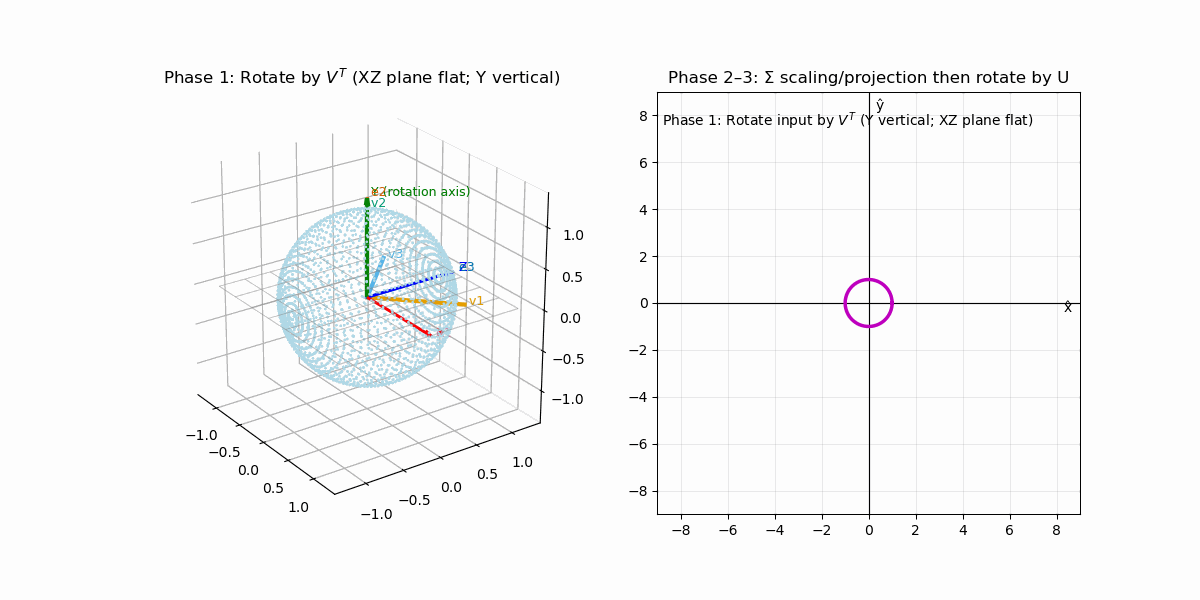

In [3]:

# Show the GIF inline (Jupyter)
from IPython.display import Image, display
display(Image(filename='SVD_VSU_animation.gif'))
